# Pedido 7 — Nueva línea base con datos de mercado de Binance

Proyecto: Detección temprana de pérdida de paridad de USDC en Binance (Terra, FTX y SVB)

**Objetivo.** Reemplazar la línea base construida con cronologías públicas por una medida con la propia serie horaria de Binance. En cada evento se buscan tres momentos (todos en UTC):

1. **Primera alerta**: primera hora con `severidad == "alerta"` (desviación ≥ 0.0011, percentil 90 del EDA).
2. **Primera hora de estrés**: primera hora con `severidad == "estres"` (desviación ≥ 0.0034).
3. **Primera hora con desviación ≥ 1 %** (`desviacion_paridad >= 0.01`), la *reacción tardía*.

La diferencia en horas entre (3) y (1) o (2) es la anticipación que ya existe en los datos.

**Reglas respetadas:** no se cambian los umbrales de severidad; no se modifican otros notebooks ni `klines_clean`; no se rellenan ni interpolan huecos; no se usan aggTrades; las horas se reportan en UTC sin redondear. La serie es **exactamente** `data/features.parquet`, la misma que alimenta al EDA y al modelo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

serie = (pd.read_parquet("../data/features.parquet")
           [["open_time_ts", "desviacion_paridad", "severidad", "fuente_paridad"]]
           .sort_values("open_time_ts").reset_index(drop=True))

# Controles de que es la misma serie del modelo
assert len(serie) == 17172, len(serie)
assert serie["open_time_ts"].is_unique
print("Filas:", len(serie), "| rango:", serie["open_time_ts"].min(), "->", serie["open_time_ts"].max())
print("Severidad:", serie["severidad"].value_counts().to_dict())
print("Fuente:", serie["fuente_paridad"].value_counts().to_dict())

# Los umbrales NO se tocan: se comprueba que coinciden con los del informe
print("Menor desviación en 'alerta':", round(serie.loc[serie.severidad == "alerta", "desviacion_paridad"].min(), 5))
print("Menor desviación en 'estres':", round(serie.loc[serie.severidad == "estres", "desviacion_paridad"].min(), 5))

Filas: 17172 | rango: 2022-01-01 00:00:00 -> 2023-12-31 23:00:00
Severidad: {'normal': 15412, 'alerta': 1587, 'estres': 173}
Fuente: {'USDCUSDT': 13524, 'BUSDUSDT_proxy': 3648}
Menor desviación en 'alerta': 0.0011
Menor desviación en 'estres': 0.0034


## 1. Ventanas de búsqueda

Se usan las mismas fechas de ventana de `03_eda.ipynb` y se amplía el inicio **7 días hacia atrás**, porque la primera alerta podría ocurrir antes de que empiece la ventana del EDA. El fin no cambia. Igual que en el EDA, el límite final es la hora 00:00 del último día (comparación `<=`).

In [2]:
EVENTOS = {
    "Terra": ("2022-05-07", "2022-05-17"),
    "FTX":   ("2022-11-05", "2022-11-15"),
    "SVB":   ("2023-03-08", "2023-03-18"),
}
DIAS_ATRAS = 7

ventanas = {}
for ev, (ini, fin) in EVENTOS.items():
    ini_amp = pd.Timestamp(ini) - pd.Timedelta(days=DIAS_ATRAS)
    fin_ts = pd.Timestamp(fin)
    w = serie[(serie.open_time_ts >= ini_amp) & (serie.open_time_ts <= fin_ts)].copy()
    w["evento"] = ev
    ventanas[ev] = w
    print(f"{ev:6s} ventana EDA: {ini} a {fin} | búsqueda ampliada: {ini_amp:%Y-%m-%d %H:%M} a {fin_ts:%Y-%m-%d %H:%M} UTC")

# Completitud: horas esperadas vs. horas con dato (no se rellena nada)
filas = []
for ev, (ini, fin) in EVENTOS.items():
    ini_amp = pd.Timestamp(ini) - pd.Timedelta(days=DIAS_ATRAS)
    esperadas = pd.date_range(ini_amp, pd.Timestamp(fin), freq="h")
    presentes = ventanas[ev].open_time_ts
    faltan = esperadas.difference(presentes)
    filas.append({"evento": ev, "horas_esperadas": len(esperadas),
                  "horas_con_dato": len(presentes), "horas_sin_dato": len(faltan),
                  "primera_hora_con_dato": presentes.min()})
completitud = pd.DataFrame(filas)
completitud

Terra  ventana EDA: 2022-05-07 a 2022-05-17 | búsqueda ampliada: 2022-04-30 00:00 a 2022-05-17 00:00 UTC
FTX    ventana EDA: 2022-11-05 a 2022-11-15 | búsqueda ampliada: 2022-10-29 00:00 a 2022-11-15 00:00 UTC
SVB    ventana EDA: 2023-03-08 a 2023-03-18 | búsqueda ampliada: 2023-03-01 00:00 a 2023-03-18 00:00 UTC


,evento,horas_esperadas,horas_con_dato,horas_sin_dato,primera_hora_con_dato
0,Terra,409,409,0,2022-04-30
1,FTX,409,409,0,2022-10-29
2,SVB,409,179,230,2023-03-10


In [3]:
# Bloques de horas sin dato dentro de cada ventana ampliada
def bloques_faltantes(ev):
    ini, fin = EVENTOS[ev]
    esperadas = pd.date_range(pd.Timestamp(ini) - pd.Timedelta(days=DIAS_ATRAS), pd.Timestamp(fin), freq="h")
    faltan = esperadas.difference(ventanas[ev].open_time_ts)
    out, s, p = [], None, None
    for t in faltan:
        if s is None:
            s = p = t
        elif t - p == pd.Timedelta(hours=1):
            p = t
        else:
            out.append((s, p)); s = p = t
    if s is not None:
        out.append((s, p))
    return out

for ev in EVENTOS:
    bl = bloques_faltantes(ev)
    if not bl:
        print(f"{ev}: sin horas faltantes en la ventana ampliada")
    for a, b in bl:
        n = int((b - a).total_seconds() / 3600) + 1
        print(f"{ev}: sin dato {a:%Y-%m-%d %H:00} a {b:%Y-%m-%d %H:00} UTC ({n} horas)")

Terra: sin horas faltantes en la ventana ampliada
FTX: sin horas faltantes en la ventana ampliada
SVB: sin dato 2023-03-01 00:00 a 2023-03-09 23:00 UTC (216 horas)
SVB: sin dato 2023-03-11 00:00 a 2023-03-11 13:00 UTC (14 horas)


## 2. Primeras horas por evento

Para cada hora encontrada se toma `fuente_paridad` de la misma fila de la serie (`USDCUSDT` = dato real, `BUSDUSDT_proxy` = sustituto).

In [4]:
def primera(w, mascara):
    r = w[mascara]
    if r.empty:
        return None
    return r.iloc[0]

def fmt(t):
    return "—" if t is None else f"{t:%Y-%m-%d %H:00}"

def tabla_primeras(umbral_pct=0.01):
    filas = []
    for ev, w in ventanas.items():
        a = primera(w, w.severidad == "alerta")
        e = primera(w, w.severidad == "estres")
        p = primera(w, w.desviacion_paridad >= umbral_pct)
        filas.append({
            "evento": ev,
            "primera_alerta": None if a is None else a.open_time_ts,
            "fuente_alerta": None if a is None else a.fuente_paridad,
            "desv_alerta": None if a is None else a.desviacion_paridad,
            "primera_estres": None if e is None else e.open_time_ts,
            "fuente_estres": None if e is None else e.fuente_paridad,
            "desv_estres": None if e is None else e.desviacion_paridad,
            "primera_umbral": None if p is None else p.open_time_ts,
            "fuente_umbral": None if p is None else p.fuente_paridad,
            "desv_umbral": None if p is None else p.desviacion_paridad,
        })
    return pd.DataFrame(filas)

primeras_1pct = tabla_primeras(0.01)
primeras_1pct

,evento,primera_alerta,fuente_alerta,desv_alerta,primera_estres,fuente_estres,desv_estres,primera_umbral,fuente_umbral,desv_umbral
0,Terra,2022-05-11 11:00:00,USDCUSDT,0.0012,2022-05-11 20:00:00,USDCUSDT,0.0051,2022-05-12 05:00:00,USDCUSDT,0.0195
1,FTX,2022-11-09 11:00:00,BUSDUSDT_proxy,0.0016,2022-11-10 04:00:00,BUSDUSDT_proxy,0.0037,2022-11-10 11:00:00,BUSDUSDT_proxy,0.0120
2,SVB,2023-03-10 21:00:00,BUSDUSDT_proxy,0.0014,2023-03-11 14:00:00,USDCUSDT,0.0871,2023-03-11 14:00:00,USDCUSDT,0.0871


In [5]:
# Versión legible (UTC, sin redondear)
leg = primeras_1pct.copy()
for c in ["primera_alerta", "primera_estres", "primera_umbral"]:
    leg[c] = leg[c].apply(fmt)
for c in ["desv_alerta", "desv_estres", "desv_umbral"]:
    leg[c] = leg[c].round(4)
leg

,evento,primera_alerta,fuente_alerta,desv_alerta,primera_estres,fuente_estres,desv_estres,primera_umbral,fuente_umbral,desv_umbral
0,Terra,2022-05-11 11:00,USDCUSDT,0.0012,2022-05-11 20:00,USDCUSDT,0.0051,2022-05-12 05:00,USDCUSDT,0.0195
1,FTX,2022-11-09 11:00,BUSDUSDT_proxy,0.0016,2022-11-10 04:00,BUSDUSDT_proxy,0.0037,2022-11-10 11:00,BUSDUSDT_proxy,0.0120
2,SVB,2023-03-10 21:00,BUSDUSDT_proxy,0.0014,2023-03-11 14:00,USDCUSDT,0.0871,2023-03-11 14:00,USDCUSDT,0.0871


## 3. Desviación máxima de cada evento

In [6]:
filas = []
for ev, w in ventanas.items():
    i = w.desviacion_paridad.idxmax()
    filas.append({"evento": ev, "hora_max": w.loc[i, "open_time_ts"],
                  "desviacion_max": w.loc[i, "desviacion_paridad"],
                  "fuente": w.loc[i, "fuente_paridad"],
                  "alcanza_1pct": bool(w.desviacion_paridad.max() >= 0.01)})
maximos = pd.DataFrame(filas)
maximos["hora_max"] = maximos["hora_max"].apply(fmt)
maximos

,evento,hora_max,desviacion_max,fuente,alcanza_1pct
0,Terra,2022-05-12 06:00,0.0500,USDCUSDT,True
1,FTX,2022-11-10 12:00,0.0129,BUSDUSDT_proxy,True
2,SVB,2023-03-11 15:00,0.0872,USDCUSDT,True


## 4. Anticipación en horas

`anticipación = primera_1pct − primera_alerta` y `primera_1pct − primera_estres`. Si un evento nunca llega al 1 %, se anota «no alcanza 1 %» y no se inventa ningún valor.

In [7]:
def horas(a, b):
    return None if (a is None or b is None or pd.isna(a) or pd.isna(b)) else (b - a).total_seconds() / 3600

def tabla_anticipacion(df):
    filas = []
    for _, r in df.iterrows():
        if pd.isna(r.primera_umbral):
            filas.append({"evento": r.evento, "umbral_hora": "no alcanza el umbral",
                          "umbral_menos_alerta_h": "no alcanza el umbral",
                          "umbral_menos_estres_h": "no alcanza el umbral"})
        else:
            filas.append({"evento": r.evento, "umbral_hora": fmt(r.primera_umbral),
                          "umbral_menos_alerta_h": horas(r.primera_alerta, r.primera_umbral),
                          "umbral_menos_estres_h": horas(r.primera_estres, r.primera_umbral)})
    return pd.DataFrame(filas)

anticipacion_1pct = tabla_anticipacion(primeras_1pct)
anticipacion_1pct

,evento,umbral_hora,umbral_menos_alerta_h,umbral_menos_estres_h
0,Terra,2022-05-12 05:00,18.0,9.0
1,FTX,2022-11-10 11:00,24.0,7.0
2,SVB,2023-03-11 14:00,17.0,0.0


## 5. Primera hora con al menos 3 horas seguidas en alerta o estrés

Una alerta de una sola hora puede ser ruido. Se cuenta como racha un conjunto de horas **consecutivas en el reloj** (diferencia exacta de 1 hora) con `severidad` distinta de `normal`; una hora sin dato corta la racha.

In [8]:
def rachas_no_normal(w):
    w = w.copy()
    w["no_normal"] = w.severidad != "normal"
    corte = (w.no_normal != w.no_normal.shift()) | (w.open_time_ts.diff() != pd.Timedelta(hours=1))
    w["grupo"] = corte.cumsum()
    r = (w[w.no_normal].groupby("grupo")
           .agg(inicio=("open_time_ts", "min"), fin=("open_time_ts", "max"),
                horas=("open_time_ts", "count"),
                fuentes=("fuente_paridad", lambda x: ", ".join(sorted(set(x))))))
    return r.reset_index(drop=True)

filas = []
for ev, w in ventanas.items():
    r = rachas_no_normal(w)
    r3 = r[r.horas >= 3]
    print(f"--- {ev}: rachas en alerta/estrés (todas) ---")
    print(r.assign(inicio=r.inicio.apply(fmt), fin=r.fin.apply(fmt)).to_string(index=False))
    if r3.empty:
        filas.append({"evento": ev, "inicio_racha_3h": "no hay", "horas_de_la_racha": None, "fuente": None})
    else:
        f = r3.iloc[0]
        filas.append({"evento": ev, "inicio_racha_3h": fmt(f.inicio), "horas_de_la_racha": int(f.horas), "fuente": f.fuentes})
rachas3 = pd.DataFrame(filas)
rachas3

--- Terra: rachas en alerta/estrés (todas) ---
          inicio              fin  horas  fuentes
2022-05-11 11:00 2022-05-13 11:00     49 USDCUSDT
2022-05-13 14:00 2022-05-17 00:00     83 USDCUSDT
--- FTX: rachas en alerta/estrés (todas) ---
          inicio              fin  horas        fuentes
2022-11-09 11:00 2022-11-15 00:00    134 BUSDUSDT_proxy
--- SVB: rachas en alerta/estrés (todas) ---
          inicio              fin  horas        fuentes
2023-03-10 21:00 2023-03-10 23:00      3 BUSDUSDT_proxy
2023-03-11 14:00 2023-03-18 00:00    155       USDCUSDT


,evento,inicio_racha_3h,horas_de_la_racha,fuente
0,Terra,2022-05-11 11:00,49,USDCUSDT
1,FTX,2022-11-09 11:00,134,BUSDUSDT_proxy
2,SVB,2023-03-10 21:00,3,BUSDUSDT_proxy


## 6. Prueba de sensibilidad con umbral de 0.5 % (0.005)

In [9]:
primeras_05 = tabla_primeras(0.005)
anticipacion_05 = tabla_anticipacion(primeras_05)
sens = primeras_05[["evento", "primera_umbral", "fuente_umbral", "desv_umbral"]].merge(anticipacion_05, on="evento")
sens["primera_umbral"] = sens["primera_umbral"].apply(fmt)
sens["desv_umbral"] = sens["desv_umbral"].round(4)
sens.drop(columns=["umbral_hora"])

,evento,primera_umbral,fuente_umbral,desv_umbral,umbral_menos_alerta_h,umbral_menos_estres_h
0,Terra,2022-05-11 20:00,USDCUSDT,0.0051,9.0,0.0
1,FTX,2022-11-10 10:00,BUSDUSDT_proxy,0.0066,23.0,6.0
2,SVB,2023-03-11 14:00,USDCUSDT,0.0871,17.0,0.0


## 7. Comprobaciones y alertas de calidad

- ¿La primera alerta coincide con la primera hora con dato de la ventana ampliada? (si es así habría que mirar más atrás)
- ¿Alguna hora encontrada cae justo después de un hueco?

In [10]:
for _, r in primeras_1pct.iterrows():
    w = ventanas[r.evento]
    inicio_datos = w.open_time_ts.min()
    print(f"{r.evento}: primera hora con dato = {fmt(inicio_datos)} | primera alerta = {fmt(r.primera_alerta)} | "
          f"¿coinciden? {r.primera_alerta == inicio_datos}")

print()
for ev, w in ventanas.items():
    blq = bloques_faltantes(ev)
    for a, b in blq:
        despues = b + pd.Timedelta(hours=1)
        fila = serie[serie.open_time_ts == despues]
        if not fila.empty:
            f = fila.iloc[0]
            print(f"{ev}: tras el hueco {a:%Y-%m-%d %H:00}–{b:%Y-%m-%d %H:00}, la primera hora con dato es "
                  f"{despues:%Y-%m-%d %H:00} (desv={f.desviacion_paridad:.4f}, {f.severidad}, {f.fuente_paridad})")

Terra: primera hora con dato = 2022-04-30 00:00 | primera alerta = 2022-05-11 11:00 | ¿coinciden? False
FTX: primera hora con dato = 2022-10-29 00:00 | primera alerta = 2022-11-09 11:00 | ¿coinciden? False
SVB: primera hora con dato = 2023-03-10 00:00 | primera alerta = 2023-03-10 21:00 | ¿coinciden? False



SVB: tras el hueco 2023-03-01 00:00–2023-03-09 23:00, la primera hora con dato es 2023-03-10 00:00 (desv=0.0002, normal, BUSDUSDT_proxy)
SVB: tras el hueco 2023-03-11 00:00–2023-03-11 13:00, la primera hora con dato es 2023-03-11 14:00 (desv=0.0871, estres, USDCUSDT)


## 8. Figura de respaldo

Serie de `desviacion_paridad` por evento (ventana ampliada), con líneas verticales en la primera alerta, la primera hora de estrés y la primera hora con 1 %. El tramo de `BUSDUSDT_proxy` va en otro color. Las horas sin dato **no se interpolan**: la línea se corta y la zona se sombrea.

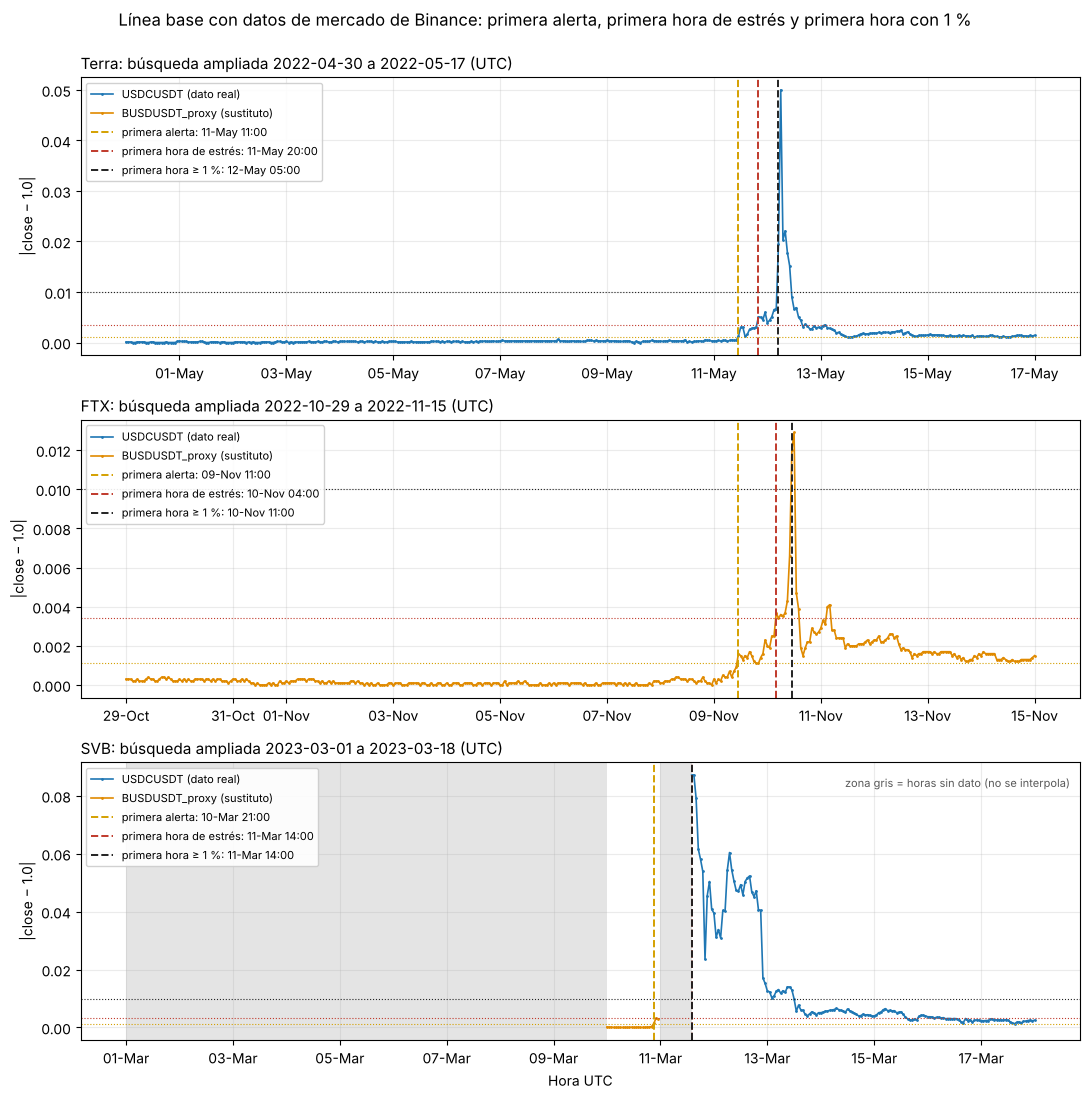

In [11]:
COL_REAL, COL_PROXY = "#1f77b4", "#e08a00"
COL_ALERTA, COL_ESTRES, COL_1PCT = "#d4a000", "#c0392b", "#222222"

fig, axes = plt.subplots(3, 1, figsize=(11, 11))
for ax, (ev, w) in zip(axes, ventanas.items()):
    ini, fin = EVENTOS[ev]
    grid = pd.date_range(pd.Timestamp(ini) - pd.Timedelta(days=DIAS_ATRAS), pd.Timestamp(fin), freq="h")
    g = w.set_index("open_time_ts").reindex(grid)
    real = g.desviacion_paridad.where(g.fuente_paridad == "USDCUSDT")
    proxy = g.desviacion_paridad.where(g.fuente_paridad == "BUSDUSDT_proxy")
    ax.plot(g.index, real, color=COL_REAL, lw=1.2, marker=".", ms=2, label="USDCUSDT (dato real)")
    ax.plot(g.index, proxy, color=COL_PROXY, lw=1.2, marker=".", ms=2, label="BUSDUSDT_proxy (sustituto)")
    # horas sin dato
    sin = g.desviacion_paridad.isna()
    for a, b in bloques_faltantes(ev):
        ax.axvspan(a, b + pd.Timedelta(hours=1), color="0.85", alpha=0.7, lw=0)
    ax.axhline(0.0011, color=COL_ALERTA, ls=":", lw=0.8)
    ax.axhline(0.0034, color=COL_ESTRES, ls=":", lw=0.8)
    ax.axhline(0.01, color=COL_1PCT, ls=":", lw=0.8)
    r = primeras_1pct[primeras_1pct.evento == ev].iloc[0]
    for t, col, nom in [(r.primera_alerta, COL_ALERTA, "primera alerta"),
                        (r.primera_estres, COL_ESTRES, "primera hora de estrés"),
                        (r.primera_umbral, COL_1PCT, "primera hora ≥ 1 %")]:
        if not pd.isna(t):
            ax.axvline(t, color=col, ls="--", lw=1.4, label=f"{nom}: {t:%d-%b %H:00}")
    ax.set_title(f"{ev}: búsqueda ampliada {grid[0]:%Y-%m-%d} a {grid[-1]:%Y-%m-%d} (UTC)", fontsize=11, loc="left")
    ax.set_ylabel("|close − 1.0|")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left", framealpha=0.9)
    if len(bloques_faltantes(ev)):
        ax.text(0.99, 0.95, "zona gris = horas sin dato (no se interpola)", transform=ax.transAxes,
                ha="right", va="top", fontsize=8, color="0.35")
axes[-1].set_xlabel("Hora UTC")
fig.suptitle("Línea base con datos de mercado de Binance: primera alerta, primera hora de estrés y primera hora con 1 %",
             fontsize=12, y=0.995)
plt.tight_layout()
plt.savefig("../informe/fig_linea_base.png", dpi=150)
plt.show()

## 9. Lectura de los resultados y límites

Las tablas de arriba son la fuente de los datos que se entregan a coordinación. Puntos a tener en cuenta al redactar el informe:

- **Terra y FTX** tienen la ventana ampliada completa (409 de 409 horas): los resultados no están afectados por huecos.
- **FTX** sí alcanza el 1 % (la desviación máxima es 0.0129), pero el dato es de `BUSDUSDT_proxy` en toda la ventana: mide el sustituto, no USDC.
- **SVB** tiene dos límites de datos. (a) No hay ninguna fila entre el 1 y el 9 de marzo de 2023: la búsqueda de 7 días hacia atrás **no se puede completar**, y la primera hora con dato es el 10 de marzo 00:00 UTC. (b) Entre el 11 de marzo 00:00 y 13:00 UTC no hay dato de USDCUSDT; la primera hora real (14:00) ya está por encima del 1 %, así que la hora real del cruce pudo ocurrir dentro del hueco. Por eso, en SVB, la anticipación medida es una **cota superior** y la hora de estrés coincide con la hora del 1 %.
- La alerta de SVB (10 de marzo 21:00) viene de `BUSDUSDT_proxy`; el estrés y el 1 % vienen de `USDCUSDT` real.
- Los 3 umbrales usados (0.0011, 0.0034, 0.01 y 0.005 en la sensibilidad) no se ajustaron a posteriori.